## Six exchanges, one schema

Bitcoin's perpetual at the six exchanges exchange-router reaches, through one
`Router.local` that runs every venue's adapter inside this process. Each venue names the
contract its own way, every frame comes back in the same columns, and the four-hour closes
of the last quarter of 2025 show how far each venue sat from the others.

In [1]:
import exchange_router
import matplotlib.pyplot
import pandas

matplotlib.pyplot.style.use(style="../oceano.mplstyle")

print(f"exchange-router {exchange_router.__version__}")

exchange-router 3.0.1


### One router for six venues

Each venue's capabilities, its own description of Bitcoin's contract, and its four-hour
candles from October to December 2025, 552 of them. `start` names the newest bar wanted
and the router walks back from it until `limit` bars are in. Hyperliquid serves the last
5,000 candles of each interval, so four-hour bars reach further back there than hourly
ones.

In [2]:
SYMBOLS = {"binance": "BTCUSDT", "bybit": "BTCUSDT", "okx": "BTCUSDT",
           "kraken": "XBTUSD", "kucoin": "XBTUSDT", "hyperliquid": "BTCUSDC"}

LAST = pandas.Timestamp("2025-12-31 20:00", tz="UTC")

with exchange_router.Router.local(exchanges=list(SYMBOLS)) as router:
    capabilities = {exchange: router.get_capabilities(exchange=exchange)
                    for exchange in SYMBOLS}
    info = {exchange: router.get_symbol_info(exchange=exchange, market_type="linear",
                                             symbol=symbol)
            for exchange, symbol in SYMBOLS.items()}
    frames = {exchange: router.get_candles(exchange=exchange, market_type="linear",
                                           symbol=symbol, interval="4h", limit=552,
                                           start=int(LAST.timestamp() * 1_000))
              for exchange, symbol in SYMBOLS.items()}

frames["kraken"].tail(n=3)

,open,high,low,close,volume,volume_usd
datetime,,,,,,
2025-12-31 12:00:00+00:00,88944.0,89157.0,87700.0,87868.0,611.0275,5.368976e+07
2025-12-31 16:00:00+00:00,87868.0,87973.0,87286.0,87454.0,377.5686,3.301988e+07
2025-12-31 20:00:00+00:00,87454.0,87817.0,87143.0,87551.0,325.6781,2.851344e+07


### What each venue serves

The routes of each venue's perpetual market, over REST or only as a stream.

In [3]:
ROUTES = ["candles", "trades", "orderbook", "funding_rate", "open_interest",
          "long_short_ratio", "liquidations"]

served = {}
for exchange, offered in capabilities.items():
    linear = offered["markets"]["linear"]
    served[exchange] = {route: "rest" if linear[route]["rest"] else
                               "stream" if linear[route]["ws"] else ""
                        for route in ROUTES}

pandas.DataFrame(served)

,binance,bybit,okx,kraken,kucoin,hyperliquid
candles,rest,rest,rest,rest,rest,rest
trades,rest,rest,rest,rest,rest,rest
orderbook,rest,rest,rest,rest,rest,rest
funding_rate,rest,rest,rest,rest,rest,rest
open_interest,rest,rest,rest,rest,rest,rest
long_short_ratio,rest,rest,rest,rest,,
liquidations,stream,stream,rest,,,


### Each venue's name for Bitcoin

Kraken and KuCoin keep the code XBT, Hyperliquid's perpetuals settle in USDC, and each
venue's own API names the contract in yet another way, which `native_symbol` keeps.
Kraken's funding accrues continuously; the others settle it at fixed times.

In [4]:
pandas.DataFrame(info.values(), index=list(info))[
    ["symbol", "native_symbol", "base_asset", "quote_asset", "min_qty", "min_notional",
     "funding_kind"]]

,symbol,native_symbol,base_asset,quote_asset,min_qty,min_notional,funding_kind
binance,BTCUSDT,BTCUSDT,BTC,USDT,0.0010,50.0,discrete
bybit,BTCUSDT,BTCUSDT,BTC,USDT,0.0010,5.0,discrete
okx,BTCUSDT,BTC-USDT-SWAP,BTC,USDT,0.0001,NaN,discrete
kraken,XBTUSD,PF_XBTUSD,XBT,USD,NaN,NaN,continuous
kucoin,XBTUSDT,XBTUSDTM,XBT,USDT,0.0010,NaN,discrete
hyperliquid,BTCUSDC,BTC,BTC,USDC,NaN,10.0,discrete


### One schema

Every frame has the same columns on a UTC index, with the constants of its query in
`attrs`: the quote currency, what the volume counts and how its dollar value was taken.

In [5]:
pandas.DataFrame([{"rows": len(frame), "first": frame.index[0], "last": frame.index[-1],
                   "columns": ", ".join(frame.columns), "quote": frame.attrs["quote"],
                   "volume in": frame.attrs["volume_unit"],
                   "dollars from": frame.attrs["usd_basis"]}
                  for frame in frames.values()], index=list(frames))

,rows,first,last,columns,quote,volume in,dollars from
binance,552,2025-10-01 00:00:00+00:00,2025-12-31 20:00:00+00:00,"open, high, low, close, volume, volume_usd",USDT,base,close
bybit,552,2025-10-01 00:00:00+00:00,2025-12-31 20:00:00+00:00,"open, high, low, close, volume, volume_usd",USDT,base,close
okx,552,2025-10-01 00:00:00+00:00,2025-12-31 20:00:00+00:00,"open, high, low, close, volume, volume_usd",USDT,base,close
kraken,552,2025-10-01 00:00:00+00:00,2025-12-31 20:00:00+00:00,"open, high, low, close, volume, volume_usd",USD,base,close
kucoin,552,2025-10-01 00:00:00+00:00,2025-12-31 20:00:00+00:00,"open, high, low, close, volume, volume_usd",USDT,base,close
hyperliquid,552,2025-10-01 00:00:00+00:00,2025-12-31 20:00:00+00:00,"open, high, low, close, volume, volume_usd",USDC,base,close


### Each close against the median of six

The median of the six closes on each bar, and each venue's close against it in basis
points. USD and USDC are taken at par with USDT, so a venue's distance also holds the drift
of its quote currency.

In [6]:
closes = pandas.DataFrame({exchange: frame["close"] for exchange, frame in frames.items()})
median = closes.median(axis="columns")

apart = closes.sub(median, axis="index").div(median, axis="index") * 10_000

apart.describe(percentiles=[0.05, 0.5, 0.95]).T.drop(columns="count").round(decimals=2)

,mean,std,min,5%,50%,95%,max
binance,-0.89,1.06,-5.57,-2.66,-0.61,0.41,2.43
bybit,-0.98,1.05,-5.72,-2.88,-0.79,0.29,1.25
okx,-1.00,1.01,-4.74,-2.88,-0.81,0.28,4.10
kraken,4.45,5.62,-29.26,-3.36,4.54,12.21,61.22
kucoin,2.86,1.31,-6.51,0.95,2.94,4.75,7.91
hyperliquid,1.72,2.89,-3.31,-1.54,0.69,7.11,11.77


### Over the quarter

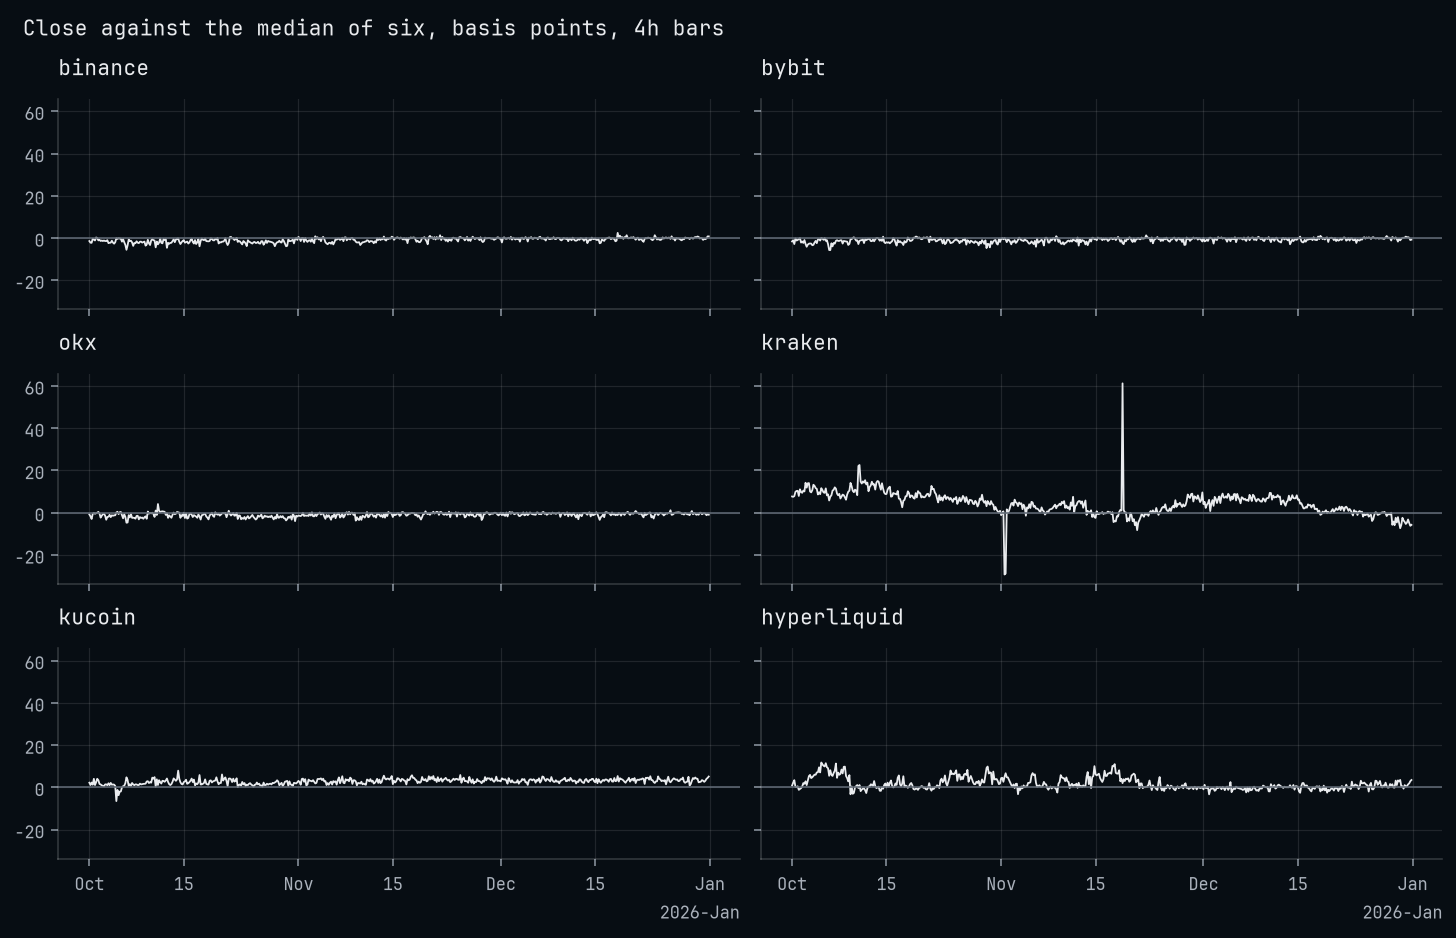

In [7]:
figure, grid = matplotlib.pyplot.subplots(nrows=3, ncols=2, sharex=True, sharey=True,
                                          figsize=(10.0, 6.4))

for axes, exchange in zip(grid.flat, apart.columns):
    axes.plot(apart.index, apart[exchange], linewidth=0.9)
    axes.axhline(y=0.0, color="C3", linewidth=0.8)
    axes.set_title(label=exchange)

figure.suptitle(t="Close against the median of six, basis points, 4h bars", x=0.01,
                ha="left", fontsize=10.5)
matplotlib.pyplot.show()

### Dollar volume at each venue

The quarter's traded volume in dollars: each bar's volume times its close, summed.

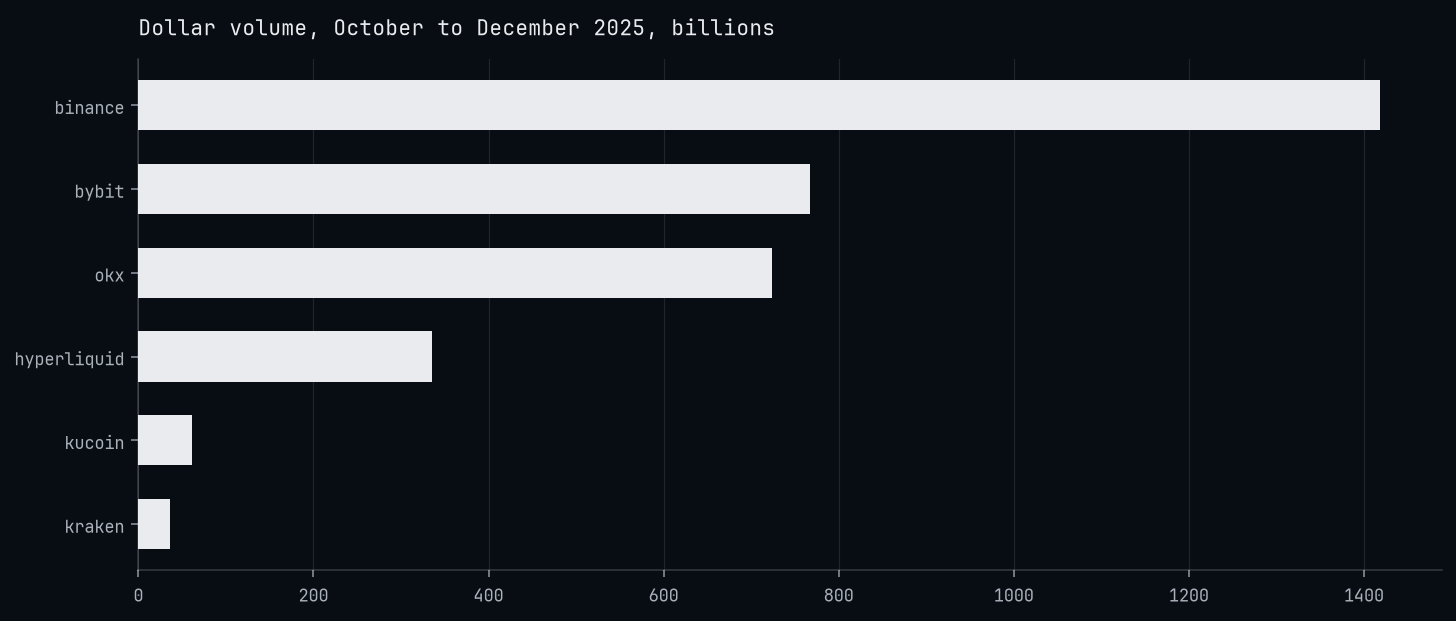

In [8]:
volume = pandas.Series({exchange: frame["volume_usd"].sum()
                        for exchange, frame in frames.items()}).sort_values()

axes = (volume / 1e9).plot(kind="barh", width=0.6, xlabel="", ylabel="",
                           title="Dollar volume, October to December 2025, billions")
axes.grid(axis="y", visible=False)
matplotlib.pyplot.show()